## Ex 2: Deep neural network for classification (MNIST)
**Aim:** To demonstrate a deep neural network model for a classification task.

**Procedure:** load and preprocess data, build model, compile and train, predict on test data, visualise with a confusion matrix.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


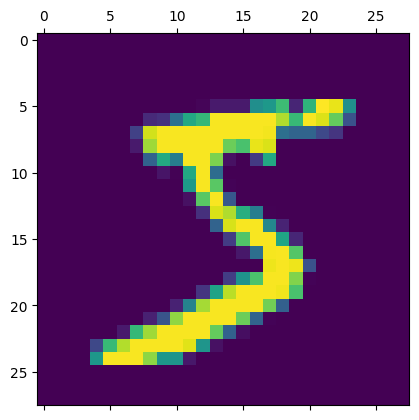

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9164 - loss: 0.3002
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9591 - loss: 0.1422
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9697 - loss: 0.1023
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9755 - loss: 0.0807
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9796 - loss: 0.0664
Test loss, accuracy: [0.0867396667599678, 0.9736999869346619]
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predicted: [7 2 1 0 4] | Actual: [7 2 1 0 4]


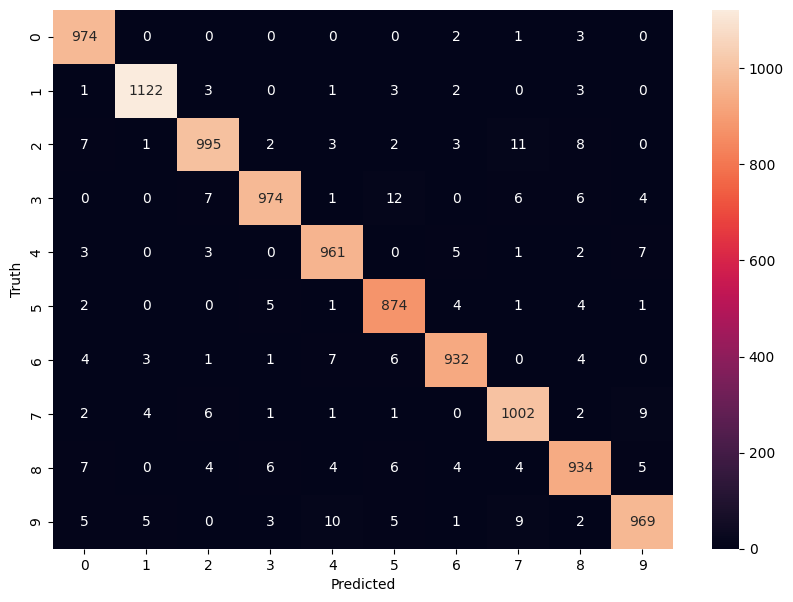

In [ ]:
import numpy as np, keras, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from keras import layers

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0
plt.matshow(x_train[0]); plt.show()

model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),                        # 28*28 = 784
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(x_train, y_train, epochs=5)
print('Test loss, accuracy:', model.evaluate(x_test, y_test, verbose=0))

y_pred = np.argmax(model.predict(x_test), axis=1)
print('Predicted:', y_pred[:5], '| Actual:', y_test[:5])

cm = tf.math.confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted'); plt.ylabel('Truth'); plt.show()